In [2]:
import pandas as pd

df = pd.read_csv('house_prices_switzerland_2024.csv')
df.head()

,ID,HouseType,Size,Price,LotSize,Balcony,LivingSpace,NumberRooms,YearBuilt,Locality,PostalCode
0,4000745035,SINGLE_HOUSE,L,1249500.0,NaN,True,270.0,7.5,NaN,Genestrerio,6852
1,4000781039,VILLA,M,1389150.0,640.0,True,230.0,8.5,2024.0,Vétroz,1963
2,4000744528,VILLA,L,NaN,NaN,True,880.0,14.0,NaN,Lugano,6900
3,4000744292,MULTIPLE_DWELLING,L,NaN,NaN,True,NaN,NaN,NaN,Grono,6537
4,4000745275,SINGLE_HOUSE,L,NaN,NaN,True,170.0,7.5,NaN,Cadempino,6814


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 973 entries, 0 to 972
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ID           973 non-null    int64  
 1   HouseType    973 non-null    str    
 2   Size         973 non-null    str    
 3   Price        908 non-null    float64
 4   LotSize      873 non-null    float64
 5   Balcony      679 non-null    object 
 6   LivingSpace  879 non-null    float64
 7   NumberRooms  905 non-null    float64
 8   YearBuilt    830 non-null    float64
 9   Locality     973 non-null    str    
 10  PostalCode   973 non-null    int64  
dtypes: float64(5), int64(2), object(1), str(3)
memory usage: 68.5+ KB


### --- Step 1.1: Data Audit & Primary Metrics ---

In [15]:
# 1. Identify bad values (NaN, 0) and calculate percentages

def count_bad_values(data, columns):
    """Calculating missing values (NaN) and values <= 0 in each column"""
    result = {}
    for col in columns:
        is_missing = data[col].isnull()
        is_invalid = data[col] <= 0
        is_bad = is_missing | is_invalid
        result[col] = {
            'Missing (NaN)': is_missing.sum(),
            'Invalid (<= 0)': is_invalid.sum(),
            'Total bad': is_bad.sum()
        }
    return pd.DataFrame(result).T


display(count_bad_values(df, ['Price', 'LivingSpace', 'NumberRooms', 'LotSize']))

# 1.1 What is in "Balcony" column?

print("--- BALCONY VALUES ---")
print(df['Balcony'].value_counts(dropna=False))

,Missing (NaN),Invalid (<= 0),Total bad
Price,65,32,97
LivingSpace,94,0,94
NumberRooms,68,0,68
LotSize,100,0,100


--- BALCONY VALUES ---
Balcony
True     635
NaN      294
False     44
Name: count, dtype: int64


In [5]:
cols_to_check = ['Price', 'LivingSpace', 'NumberRooms', 'LotSize', 'YearBuilt']

# Dataset True/False: which one has a problem
is_missing = df[cols_to_check].isnull()
is_invalid = df[cols_to_check] <= 0
problems = is_missing | is_invalid

# The row is 'bad' if at least 1 column has an issue
bad_rows = problems.any(axis=1)

df_clean = df[~bad_rows].copy()
df_quarantine = df[bad_rows].copy()

print(f"Total:      {len(df)}")
print(f"Clean:      {len(df_clean)}")
print(f"Quarantine: {len(df_quarantine)}")

Total:      973
Clean:      635
Quarantine: 338


In [6]:
balcony_map = {True: 'Yes', False: 'No'}

df_clean['Balcony'] = df_clean['Balcony'].map(balcony_map).fillna('Unknown')

print(df_clean['Balcony'].value_counts(dropna=False))

Balcony
Yes        439
Unknown    167
No          29
Name: count, dtype: int64


In [7]:
# 2. Defining the price per SqM

df_clean['Price_per_SqM'] = df_clean['Price'] / df_clean['LivingSpace']

df_clean[['Price', 'LivingSpace', 'Price_per_SqM', 'NumberRooms']].describe().round(0)

,Price,LivingSpace,Price_per_SqM,NumberRooms
count,635.0,635.0,635.0,635.0
mean,2179532.0,291.0,7783.0,10.0
std,1928219.0,152.0,3529.0,3.0
min,470400.0,105.0,775.0,3.0
25%,1323000.0,200.0,5548.0,8.0
50%,1822800.0,250.0,7293.0,9.0
75%,2499000.0,330.0,9391.0,10.0
max,25725000.0,1610.0,33075.0,44.0


#### Checking extreme values of price per m²
`describe()` showed min = 775 CHF/m² and max = 33,075 CHF/m².
The maximum is plausible (luxury villas), but the minimum is suspiciously low for Switzerland.
**Hypothesis:** some cheap listings are data errors (price for a share, rent, wrong living space).
We inspect the actual rows before removing anything.

In [8]:
# Show only the columns that help decide whether a row is an error or a real property
cols = ['HouseType', 'Price', 'LivingSpace', 'Price_per_SqM', 'Locality', 'YearBuilt']

# Cheapest per m²: test the hypothesis that these are data errors
print("--- 10 CHEAPEST PER m² ---")
display(df_clean.nsmallest(10, 'Price_per_SqM')[cols])

# Most expensive per m²: confirm these are real luxury properties, not typos
print("--- 10 MOST EXPENSIVE PER m² ---")
display(df_clean.nlargest(10, 'Price_per_SqM')[cols])

--- 10 CHEAPEST PER m² ---


,HouseType,Price,LivingSpace,Price_per_SqM,Locality,YearBuilt
723,SINGLE_HOUSE,852600.0,1100.0,775.090909,Les Verrières,1902.0
895,SINGLE_HOUSE,940800.0,1100.0,855.272727,Liddes,1947.0
432,MULTIPLE_DWELLING,926100.0,980.0,945.000000,Walenstadtberg,1889.0
827,SINGLE_HOUSE,720300.0,490.0,1470.000000,Fontenais,1850.0
744,SINGLE_HOUSE,764400.0,510.0,1498.823529,Courgenay,1964.0
773,ROW_HOUSE,470400.0,300.0,1568.000000,Orsières,1958.0
867,BIFAMILIAR_HOUSE,940800.0,580.0,1622.068966,Courtemaîche,1982.0
711,SINGLE_HOUSE,727650.0,400.0,1819.125000,Rebeuvelier,1947.0
602,SINGLE_HOUSE,1425900.0,730.0,1953.287671,Choëx,1988.0
797,SINGLE_HOUSE,1764000.0,880.0,2004.545455,Brenles,1851.0


--- 10 MOST EXPENSIVE PER m² ---


,HouseType,Price,LivingSpace,Price_per_SqM,Locality,YearBuilt
611,ROW_HOUSE,5292000.0,160.0,33075.000000,Zürich,1931.0
368,VILLA,6468000.0,220.0,29400.000000,Ronco sopra Ascona,1960.0
257,VILLA,25725000.0,1020.0,25220.588235,Gommiswald,2012.0
525,ROW_HOUSE,2425500.0,127.0,19098.425197,Zürich,1899.0
221,SINGLE_HOUSE,3050250.0,160.0,19064.062500,Marin-Epagnier,2023.0
83,CHALET,3667650.0,200.0,18338.250000,Schluein,2023.0
577,SINGLE_HOUSE,4483500.0,250.0,17934.000000,Lausanne,1927.0
441,CHALET,14699980.0,820.0,17926.804878,La Brévine,2010.0
351,VILLA,21315000.0,1200.0,17762.500000,Brunnen,2010.0
810,SINGLE_HOUSE,10272360.0,580.0,17710.965517,La Conversion,1962.0


**Conclusion:** cheapest listings are mostly old houses in rural areas (Jura, Valais),
often with very large living space (possibly incl. barns/annexes). They look like real properties,
not typos, so we keep them. Old houses in Zürich are still expensive → location seems to matter more than age.
**Next:** test whether building age is related to price per m² across the whole dataset.

In [9]:
# Group houses into construction periods to test whether age affects price per m²
bins = [0, 1919, 1945, 1970, 1990, 2010, 2030]
labels = ['before 1919', '1919-1945', '1946-1970', '1971-1990', '1991-2010', 'after 2010']

df_clean['Period'] = pd.cut(df_clean['YearBuilt'], bins=bins, labels=labels)

# Median is used instead of mean because prices are skewed by luxury outliers
df_clean.groupby('Period', observed=True)['Price_per_SqM'].agg(['median', 'count']).round(0)

,median,count
Period,,
before 1919,4900.0,97
1919-1945,8053.0,39
1946-1970,7056.0,101
1971-1990,7586.0,134
1991-2010,7656.0,127
after 2010,7818.0,137


In [10]:
# Check the mix of house types in each period:
# differences in price may come from WHAT was built, not WHEN
type_mix = pd.crosstab(df_clean['Period'], df_clean['HouseType'], normalize='index') * 100

type_mix.round(0)


HouseType,BIFAMILIAR_HOUSE,CHALET,FARM_HOUSE,MULTIPLE_DWELLING,ROW_HOUSE,SINGLE_HOUSE,TERRACE_HOUSE,VILLA
Period,,,,,,,,
before 1919,11.0,1.0,9.0,8.0,12.0,57.0,0.0,1.0
1919-1945,13.0,5.0,3.0,10.0,13.0,49.0,0.0,8.0
1946-1970,13.0,1.0,1.0,0.0,11.0,70.0,0.0,4.0
1971-1990,14.0,3.0,1.0,1.0,16.0,56.0,0.0,8.0
1991-2010,18.0,5.0,0.0,1.0,17.0,52.0,2.0,5.0
after 2010,23.0,4.0,1.0,0.0,7.0,59.0,0.0,6.0


In [11]:
# 2.1. Categorisation by cantons/regions

# The first digit of a Swiss postal code is a postal district, not a canton
# (e.g. 6855 Stabio is in Ticino, 2500 Biel in Bern), so we join on the FULL postal code.
# Source of the reference table: GeoNames (CC BY 4.0)
geo_ref = pd.read_csv('swiss_postal_codes.csv')

rows_before = len(df_clean)
df_clean = df_clean.merge(geo_ref, on='PostalCode', how='left')

# Sanity checks: the join must not duplicate rows, and every postal code should be found
print(f"Rows before: {rows_before}, after: {len(df_clean)}")
print(f"Unmapped postal codes: {df_clean['Canton'].isnull().sum()}")

df_clean[['PostalCode', 'Locality', 'Canton', 'CantonName', 'Region']].head()

Rows before: 635, after: 635
Unmapped postal codes: 0


,PostalCode,Locality,Canton,CantonName,Region
0,1963,Vétroz,VS,Valais,Lake Geneva Region
1,2826,Corban,JU,Jura,Espace Mittelland
2,7405,Rothenbrunnen,GR,Graubünden,Eastern Switzerland
3,2500,Biel/Bienne,BE,Berne,Espace Mittelland
4,2500,Biel/Bienne,BE,Berne,Espace Mittelland


In [12]:
# Location hypothesis: does price per m² differ between cantons more than between house types?
canton_stats = df_clean.groupby(['Canton', 'CantonName']).agg(
    median_price_sqm=('Price_per_SqM', 'median'),
    count=('Price_per_SqM', 'count')
).sort_values('median_price_sqm', ascending=False)

# Cantons with very few listings give unreliable medians, so we show the count next to each value
canton_stats.round(0)


,,median_price_sqm,count
Canton,CantonName,,
ZG,Zug,17294.0,1
GE,Genève,12075.0,11
UR,Uri,10395.0,1
BS,Basel-Stadt,10290.0,3
SZ,Schwyz,10023.0,5
ZH,Zürich,9831.0,62
GR,Graubünden,9379.0,7
LU,Luzern,9105.0,16
BL,Basel-Landschaft,8232.0,53


In [13]:
# Medians based on very few listings are unreliable (e.g. Zug has only 1 listing),
# so we only rank cantons with enough data
MIN_LISTINGS = 10

reliable_cantons = canton_stats[canton_stats['count'] >= MIN_LISTINGS]
small_cantons = canton_stats[canton_stats['count'] < MIN_LISTINGS]

print(f"Reliable cantons: {len(reliable_cantons)}, excluded: {len(small_cantons)}")
display(reliable_cantons.round(0))


Reliable cantons: 16, excluded: 8


,,median_price_sqm,count
Canton,CantonName,,
GE,Genève,12075.0,11
ZH,Zürich,9831.0,62
LU,Luzern,9105.0,16
BL,Basel-Landschaft,8232.0,53
TI,Ticino,8057.0,31
TG,Thurgau,7656.0,29
AG,Aargau,7598.0,60
SG,St. Gallen,7427.0,29
VD,Vaud,7350.0,73


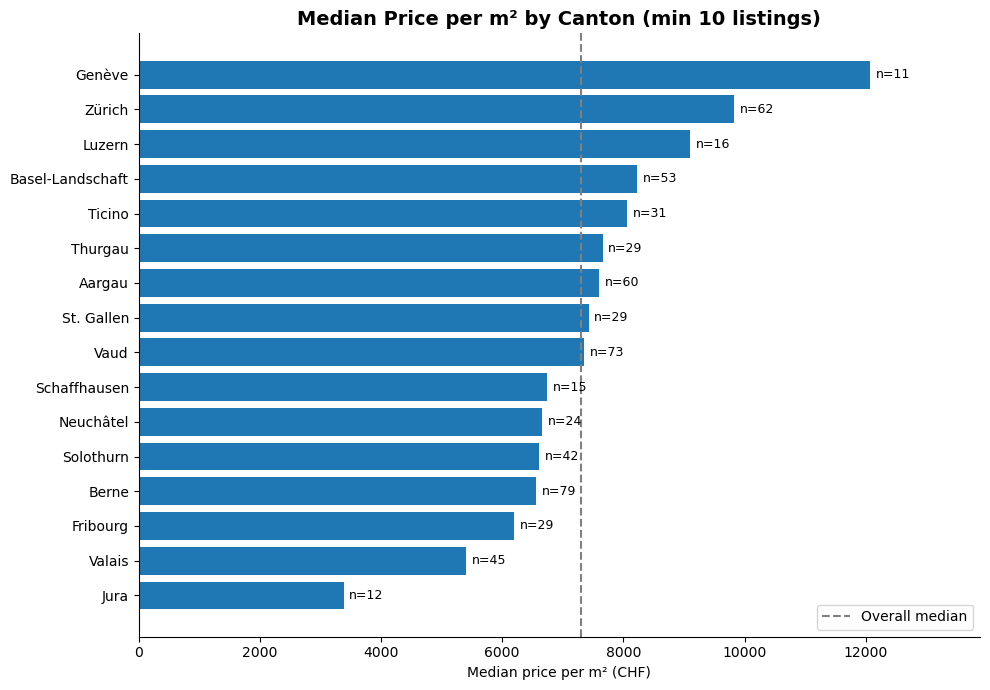

In [14]:
# 2.2 Visualizing canton ratings

import matplotlib.pyplot as plt

# reset_index() turns Canton/CantonName back into regular columns, so we can use them for labels.
# Sort ascending: in a horizontal bar chart the last bar is drawn at the top,
# so the most expensive canton ends up on top.
plot_data = reliable_cantons.reset_index().sort_values('median_price_sqm')

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(plot_data['CantonName'], plot_data['median_price_sqm'], color='#1f77b4')

# Show the number of listings next to each bar so readers can judge how reliable it is
ax.bar_label(bars, labels=[f"n={n}" for n in plot_data['count']], padding=4, fontsize=9)

# Reference line: median across all clean listings, to see which cantons are above/below average
ax.axvline(df_clean['Price_per_SqM'].median(), color='grey', linestyle='--', label='Overall median')

ax.set_title(f'Median Price per m² by Canton (min {MIN_LISTINGS} listings)', fontsize=14, fontweight='bold')
ax.set_xlabel('Median price per m² (CHF)')
ax.legend()

# Add 15% extra space on the right so the "n=..." labels fit inside the frame
ax.set_xlim(0, plot_data['median_price_sqm'].max() * 1.15)

# Remove the top and right borders: they carry no information and make the chart look cleaner
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()
